# Câu 2. Khám phá dữ liệu

In [8]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from nltk.probability import FreqDist
from wordcloud import WordCloud

## Đọc dữ liệu đã tiền xử lý

In [9]:
path_in = "../Data_Preprocessing"

List_Files = sorted([f for f in os.listdir(path_in) if f.endswith(".txt")])
text_pre = []   
for file_name in List_Files:
    f = open(os.path.join(path_in, file_name), "r", encoding="utf-8")
    text_pre = text_pre + f.read().split()
    f.close()

print("Số file:", len(List_Files))
print("Số từ (Number of words):", len(text_pre))
print("Số từ vựng (khác nhau):", len(set(text_pre)))

Số file: 172
Số từ (Number of words): 6039
Số từ vựng (khác nhau): 2071


## a. Thống kê tần suất từ xuất hiện trong văn bản

In [10]:

frequency_dist = FreqDist(text_pre)

print(frequency_dist.most_common(50))

[('quán', 154), ('đi', 90), ('ngon', 87), ('món', 83), ('nhân_viên', 76), ('phục_vụ', 68), ('giá', 68), ('gọi', 54), ('xe', 49), ('mua', 49), ('uống', 48), ('lắm', 47), ('tiền', 45), ('bánh', 45), ('hơi', 44), ('bàn', 40), ('kêu', 36), ('thử', 36), ('xong', 35), ('trà', 34), ('đông', 34), ('đợi', 33), ('thịt', 33), ('mấy', 29), ('không_gian', 29), ('đồ_ăn', 29), ('cua', 29), ('chỗ', 29), ('order', 28), ('vị', 28), ('chả', 26), ('bình_thường', 25), ('nướng', 24), ('bảo', 24), ('đồ', 23), ('sữa', 22), ('đem', 22), ('lẩu', 22), ('mặt', 20), ('đầu', 20), ('chất_lượng', 20), ('chờ', 20), ('ok', 19), ('trứng', 19), ('chiên', 19), ('hôm', 19), ('cơm', 18), ('ghé', 18), ('rau', 18), ('đĩa', 18)]


In [11]:

df_freq = pd.DataFrame(frequency_dist.most_common(), columns=["Từ", "Tần suất"])
df_freq.to_csv("tan_suat_tu.csv", index=False, encoding="utf-8-sig")
df_freq.head(20)

,Từ,Tần suất
0,quán,154
1,đi,90
2,ngon,87
3,món,83
4,nhân_viên,76
5,phục_vụ,68
6,giá,68
7,gọi,54
8,xe,49
9,mua,49


## b. Trực quan hóa bằng đồ thị và word cloud
### Đồ thị tần suất

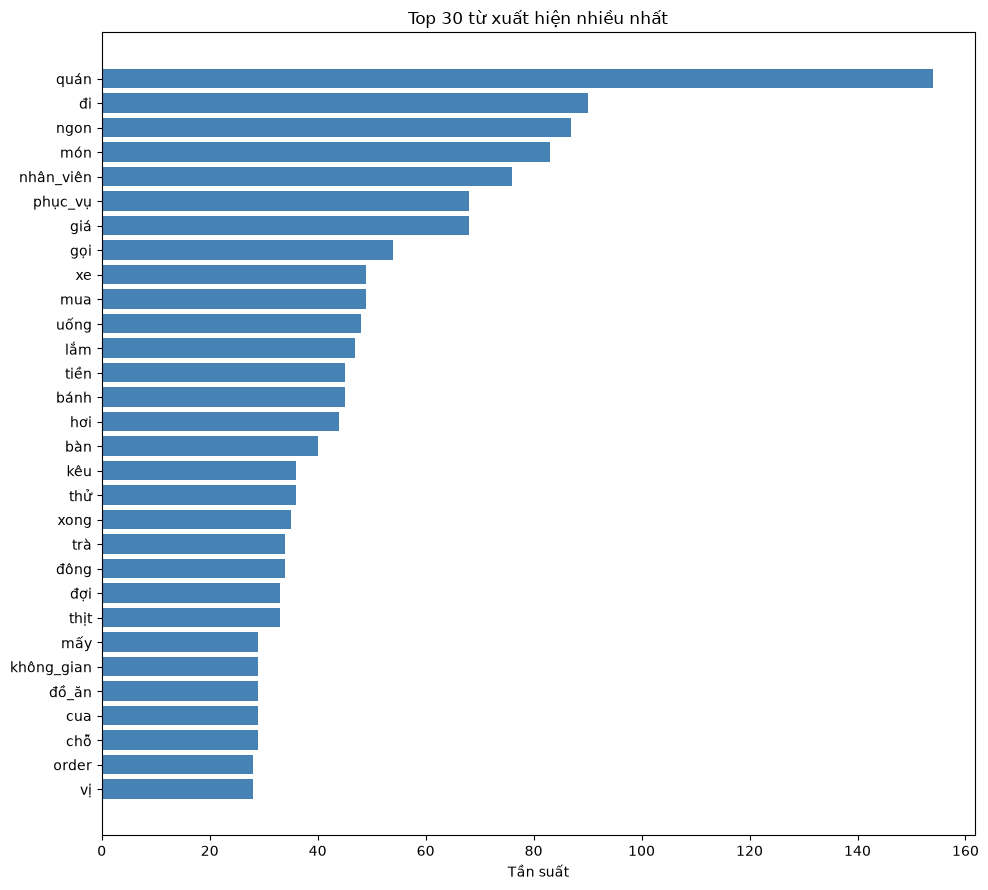

In [12]:

top30 = df_freq.head(30)
plt.figure(figsize=(10, 9))
plt.barh(top30["Từ"][::-1], top30["Tần suất"][::-1], color="steelblue")
plt.title("Top 30 từ xuất hiện nhiều nhất")
plt.xlabel("Tần suất")
plt.tight_layout()
plt.savefig("bieu_do_tan_suat.png", dpi=150)
plt.show()

### Word cloud

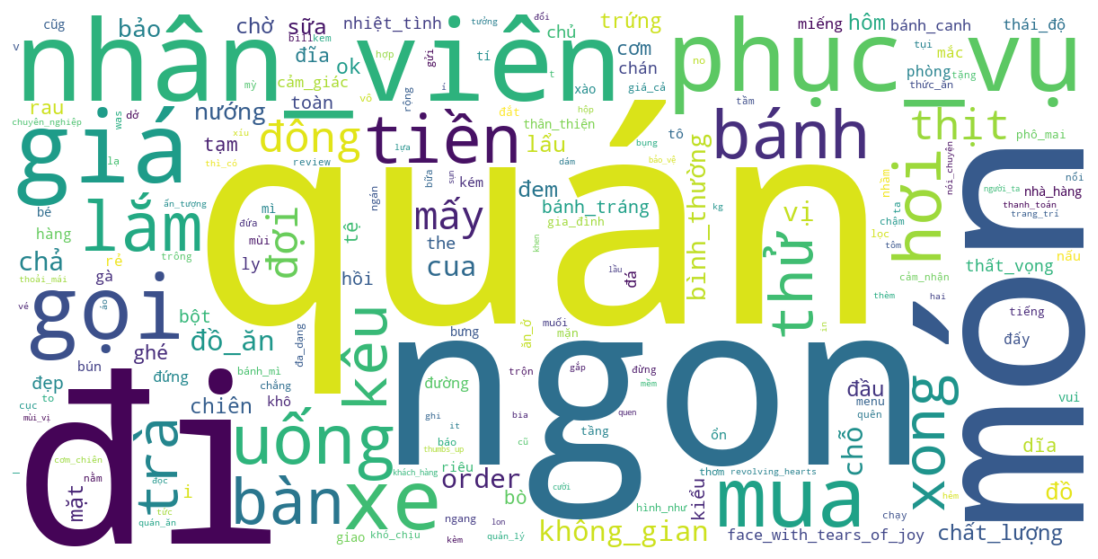

In [13]:

wcloud = WordCloud(width=1200, height=600, background_color="white", max_words=200).generate_from_frequencies(frequency_dist)
plt.figure(figsize=(14, 7))
plt.imshow(wcloud, interpolation="bilinear")
plt.axis("off")
plt.savefig("word_cloud.png", dpi=150, bbox_inches="tight")
plt.show()